# Predicting 30-Day Hospital Readmission for Patients with Diabetes
### A self-learning tutorial: XGBoost + SHAP explainability on the UCI "Diabetes 130-US Hospitals" dataset

**What you will build:** a machine-learning model that predicts whether a diabetic patient will be
readmitted to the hospital within 30 days of discharge, then *explain* the model's predictions.

**Why it matters:** 30-day readmissions are costly and are tracked by the U.S. Hospital Readmissions
Reduction Program (HRRP). A model that flags high-risk patients at discharge lets care teams target
follow-up calls, medication reconciliation, or early clinic visits.

**What you will learn**
1. Load and clean a real (messy) EHR-derived dataset
2. Avoid the #1 leakage trap in patient data: *repeat encounters of the same patient*
3. Turn ICD-9 diagnosis codes into clinically meaningful groups
4. Train a baseline (logistic regression) and a gradient-boosted tree model (XGBoost)
5. Evaluate correctly on an imbalanced outcome (ROC-AUC, **PR-AUC**, calibration, thresholds)
6. Explain predictions globally and for a single patient with **SHAP**
7. Check performance across patient subgroups (fairness audit)

**Dataset:** Strack et al. (2014), *Impact of HbA1c Measurement on Hospital Readmission Rates*,
BioMed Research International. 101,766 encounters from 130 U.S. hospitals (1999–2008).
Public, de-identified, no credentialing required: https://archive.ics.uci.edu/dataset/296

**How to run:** Works in Google Colab or local Jupyter (Python ≥ 3.9). Run cells top-to-bottom.
Total runtime ≈ 1–3 minutes on a laptop CPU.

## Step 0 — Install and import libraries

In [1]:
# Uncomment the next line if you are in Colab or a fresh environment.
# !pip install -q pandas numpy scikit-learn xgboost shap matplotlib seaborn

import io, os, zipfile, urllib.request, json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (roc_auc_score, average_precision_score, roc_curve,
                             precision_recall_curve, confusion_matrix, brier_score_loss,
                             classification_report)
from sklearn.calibration import calibration_curve
import xgboost as xgb
import shap

# A fixed random seed makes every result in this tutorial reproducible.
SEED = 42
np.random.seed(SEED)

# Folder where we save figures (these figures are reused in the slides).
os.makedirs("figures", exist_ok=True)
sns.set_theme(style="whitegrid")
print("xgboost", xgb.__version__, "| shap", shap.__version__)

xgboost 3.4.1 | shap 0.53.0


## Step 1 — Download the data
The UCI archive serves a zip file containing `diabetic_data.csv` (the encounters) and
`IDs_mapping.csv` (code look-ups). We download it once and cache it in `data/`.

In [2]:
URL = ("https://archive.ics.uci.edu/static/public/296/"
       "diabetes+130-us+hospitals+for+years+1999-2008.zip")
DATA_DIR = "data"
CSV_NAME = "diabetic_data.csv"

def find_csv(root):
    # The zip may extract into a sub-folder, so search for the file instead of hard-coding a path.
    for dirpath, _, files in os.walk(root):
        if CSV_NAME in files:
            return os.path.join(dirpath, CSV_NAME)
    return None

csv_path = find_csv(DATA_DIR) if os.path.isdir(DATA_DIR) else None
if csv_path is None:
    print("Downloading dataset ...")
    raw = urllib.request.urlopen(URL).read()
    zipfile.ZipFile(io.BytesIO(raw)).extractall(DATA_DIR)
    csv_path = find_csv(DATA_DIR)

# The dataset encodes missing values as "?" -> tell pandas to treat them as NaN.
df_raw = pd.read_csv(csv_path, na_values="?", low_memory=False)
print(df_raw.shape)
df_raw.head()

(101766, 50)


,encounter_id,patient_nbr,race,gender,age,weight,admission_type_id,discharge_disposition_id,admission_source_id,time_in_hospital,...,citoglipton,insulin,glyburide-metformin,glipizide-metformin,glimepiride-pioglitazone,metformin-rosiglitazone,metformin-pioglitazone,change,diabetesMed,readmitted
0,2278392,8222157,Caucasian,Female,[0-10),NaN,6,25,1,1,...,No,No,No,No,No,No,No,No,No,NO
1,149190,55629189,Caucasian,Female,[10-20),NaN,1,1,7,3,...,No,Up,No,No,No,No,No,Ch,Yes,>30
2,64410,86047875,AfricanAmerican,Female,[20-30),NaN,1,1,7,2,...,No,No,No,No,No,No,No,No,Yes,NO
3,500364,82442376,Caucasian,Male,[30-40),NaN,1,1,7,2,...,No,Up,No,No,No,No,No,Ch,Yes,NO
4,16680,42519267,Caucasian,Male,[40-50),NaN,1,1,7,1,...,No,Steady,No,No,No,No,No,Ch,Yes,NO


## Step 2 — Explore the data
Each **row is one hospital encounter** (admission). Key columns:

| Column(s) | Meaning |
|---|---|
| `encounter_id`, `patient_nbr` | encounter and patient identifiers |
| `race`, `gender`, `age` | demographics (age is in 10-year bins like `[70-80)`) |
| `admission_type_id`, `discharge_disposition_id`, `admission_source_id` | coded admin fields |
| `time_in_hospital`, `num_lab_procedures`, `num_medications`, ... | utilization during the stay |
| `number_outpatient/emergency/inpatient` | visits in the **year before** this encounter |
| `diag_1/2/3` | primary + secondary ICD-9 diagnoses |
| `A1Cresult`, `max_glu_serum` | lab results |
| 23 drug columns (`metformin`, `insulin`, ...) | `No` / `Steady` / `Up` / `Down` |
| `readmitted` | **target**: `<30`, `>30`, or `NO` |

In [3]:
# How is the outcome distributed?
print(df_raw["readmitted"].value_counts(normalize=True).round(3))

# Which columns are mostly missing? (Columns with >40% missing are hard to use.)
missing = df_raw.isna().mean().sort_values(ascending=False)
missing[missing > 0].round(3)

readmitted
NO     0.539
>30    0.349
<30    0.112
Name: proportion, dtype: float64


weight               0.969
max_glu_serum        0.947
A1Cresult            0.833
medical_specialty    0.491
payer_code           0.396
race                 0.022
diag_3               0.014
diag_2               0.004
diag_1               0.000
dtype: float64

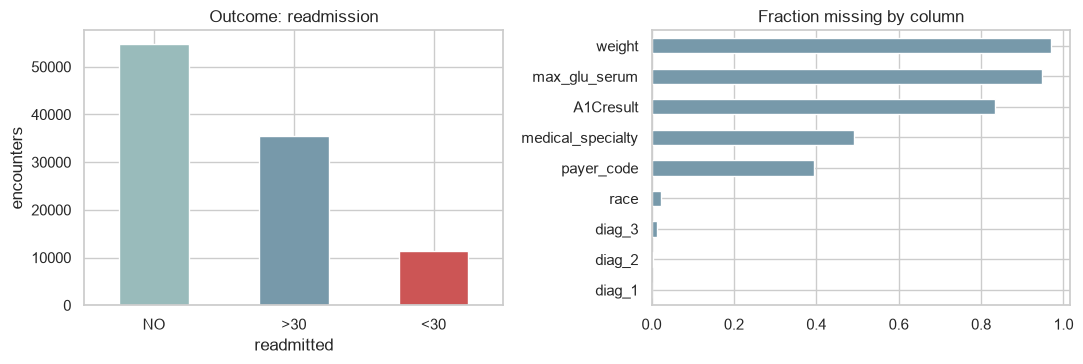

In [4]:
fig, ax = plt.subplots(1, 2, figsize=(11, 3.8))
df_raw["readmitted"].value_counts().reindex(["NO", ">30", "<30"]).plot.bar(ax=ax[0], color=["#9bb", "#79a", "#c55"])
ax[0].set_title("Outcome: readmission"); ax[0].set_ylabel("encounters"); ax[0].tick_params(axis="x", rotation=0)
m = missing[missing > 0]
m.plot.barh(ax=ax[1], color="#79a"); ax[1].set_title("Fraction missing by column"); ax[1].invert_yaxis()
plt.tight_layout(); plt.savefig("figures/eda.png", dpi=160); plt.show()

**Observations**
* Only ~11% of encounters are readmitted within 30 days → an **imbalanced** problem. Accuracy will be
  misleading (predicting "no" for everyone is 89% accurate!).
* `weight` (~97% missing), `max_glu_serum` and `A1Cresult` are mostly missing. Lab "missing" here
  usually means *not measured*, which is itself informative, so we keep labs as a `"None"` category
  but drop `weight`.

## Step 3 — Clean the data (and avoid leakage)
Three cleaning decisions, each with a clinical or statistical reason:

1. **Remove patients who died or went to hospice.** They *cannot* be readmitted, so including them
   teaches the model a trivial pattern. Discharge codes 11, 19, 20, 21 = expired; 13, 14 = hospice.
2. **Keep only each patient's first encounter.** ~30% of rows are repeat visits by the same patient.
   If the same patient lands in both train and test, the model memorizes the person and test scores
   are inflated. Keeping one encounter per patient makes every row independent.
3. **Binary target:** `1` if readmitted `<30` days, else `0` (`>30` and `NO` are both "not early").

In [5]:
df = df_raw.copy()

# 1) Drop expired / hospice discharges.
EXPIRED_OR_HOSPICE = [11, 13, 14, 19, 20, 21]
df = df[~df["discharge_disposition_id"].isin(EXPIRED_OR_HOSPICE)]

# 2) Keep the first encounter per patient (encounter_id increases over time).
df = df.sort_values("encounter_id").drop_duplicates("patient_nbr", keep="first")

# 3) Binary target.
df["target"] = (df["readmitted"] == "<30").astype(int)

# Drop identifiers, the raw target, and columns that are mostly empty.
df = df.drop(columns=["encounter_id", "patient_nbr", "readmitted", "weight", "payer_code"])

# Gender has 3 "Unknown/Invalid" rows - remove them.
df = df[df["gender"] != "Unknown/Invalid"]

print(f"Rows after cleaning: {len(df):,}  |  30-day readmission rate: {df['target'].mean():.3f}")

Rows after cleaning: 69,987  |  30-day readmission rate: 0.090


## Step 4 — Feature engineering
Raw ICD-9 codes have ~700 distinct values, which is too sparse to learn from. Following Strack et al. (2014),
we group them into clinically meaningful categories (circulatory, respiratory, diabetes, ...).
We also turn age bins into numbers and summarize the 23 medication columns.

In [6]:
def icd9_group(code):
    # Map an ICD-9 code string to a broad clinical category (Strack et al., 2014, Table 2).
    if pd.isna(code):
        return "Missing"
    if code.startswith(("V", "E")):          # V = supplementary, E = external causes of injury
        return "Other"
    c = float(code)
    if 390 <= c <= 459 or c == 785: return "Circulatory"
    if 460 <= c <= 519 or c == 786: return "Respiratory"
    if 520 <= c <= 579 or c == 787: return "Digestive"
    if int(c) == 250:               return "Diabetes"
    if 800 <= c <= 999:             return "Injury"
    if 710 <= c <= 739:             return "Musculoskeletal"
    if 580 <= c <= 629 or c == 788: return "Genitourinary"
    if 140 <= c <= 239:             return "Neoplasms"
    return "Other"

for col in ["diag_1", "diag_2", "diag_3"]:
    df[col + "_group"] = df[col].astype(str).replace("nan", np.nan).map(icd9_group)
df = df.drop(columns=["diag_1", "diag_2", "diag_3"])

# Age "[70-80)" -> 75 (midpoint), so the model sees age as ordered numbers.
df["age_num"] = df["age"].str.extract(r"\[(\d+)-").astype(int)[0] + 5
df = df.drop(columns=["age"])

# Medication summary features.
MED_COLS = ["metformin", "repaglinide", "nateglinide", "chlorpropamide", "glimepiride",
            "acetohexamide", "glipizide", "glyburide", "tolbutamide", "pioglitazone",
            "rosiglitazone", "acarbose", "miglitol", "troglitazone", "tolazamide", "examide",
            "citoglipton", "insulin", "glyburide-metformin", "glipizide-metformin",
            "glimepiride-pioglitazone", "metformin-rosiglitazone", "metformin-pioglitazone"]
df["n_diabetes_meds"] = (df[MED_COLS] != "No").sum(axis=1)       # how many diabetes drugs
df["n_med_changes"] = df[MED_COLS].isin(["Up", "Down"]).sum(axis=1)  # dose changed this stay
# Keep the two most common drugs as-is; drop the rarely-used ones (almost always "No").
df = df.drop(columns=[c for c in MED_COLS if c not in ("metformin", "insulin")])

# Prior-year utilization: a strong, well-known readmission signal.
df["total_prior_visits"] = df["number_outpatient"] + df["number_emergency"] + df["number_inpatient"]

# Missing categorical values become an explicit "Missing" / "None" level.
df["race"] = df["race"].fillna("Missing")
df["medical_specialty"] = df["medical_specialty"].fillna("Missing")
df["A1Cresult"] = df["A1Cresult"].fillna("None")
df["max_glu_serum"] = df["max_glu_serum"].fillna("None")

# Keep only the 15 most frequent specialties; group the long tail as "Other".
top_spec = df["medical_specialty"].value_counts().index[:15]
df["medical_specialty"] = df["medical_specialty"].where(df["medical_specialty"].isin(top_spec), "Other")

# The *_id columns are codes, not quantities -> treat them as categories.
for c in ["admission_type_id", "discharge_disposition_id", "admission_source_id"]:
    df[c] = df[c].astype(str)

print(df.shape)
df.head()

(69987, 28)

,race,gender,admission_type_id,discharge_disposition_id,admission_source_id,time_in_hospital,medical_specialty,num_lab_procedures,num_procedures,num_medications,...,change,diabetesMed,target,diag_1_group,diag_2_group,diag_3_group,age_num,n_diabetes_meds,n_med_changes,total_prior_visits
8,Caucasian,Female,2,1,4,13,Missing,68,2,28,...,Ch,Yes,0,Circulatory,Circulatory,Other,85,2,0,0
9,Caucasian,Female,3,3,4,12,InternalMedicine,33,3,18,...,Ch,Yes,0,Circulatory,Neoplasms,Respiratory,95,2,0,0
4,Caucasian,Male,1,1,7,1,Missing,51,0,8,...,Ch,Yes,0,Neoplasms,Neoplasms,Diabetes,45,2,0,0
10,AfricanAmerican,Female,1,1,7,9,Missing,47,2,17,...,No,Yes,0,Diabetes,Circulatory,Injury,45,1,0,0
5,Caucasian,Male,2,1,2,3,Missing,31,6,16,...,No,Yes,0,Circulatory,Circulatory,Diabetes,55,1,0,0


## Step 5 — Train / validation / test split
* **Test (20%)** is locked away until the very end.
* **Validation (16%)** is carved out of training data for XGBoost early stopping.
* `stratify=y` keeps the ~9% positive rate identical in every split.

In [7]:
y = df["target"].values
X = df.drop(columns=["target"])
CAT_COLS = [c for c in X.columns if not pd.api.types.is_numeric_dtype(X[c])]   # text columns
NUM_COLS = [c for c in X.columns if pd.api.types.is_numeric_dtype(X[c])]

X_trval, X_test, y_trval, y_test = train_test_split(X, y, test_size=0.20, stratify=y, random_state=SEED)
X_train, X_val, y_train, y_val = train_test_split(X_trval, y_trval, test_size=0.20, stratify=y_trval, random_state=SEED)
print(f"train {len(X_train):,} | val {len(X_val):,} | test {len(X_test):,}")
print(f"{len(NUM_COLS)} numeric features, {len(CAT_COLS)} categorical features")

train 44,791 | val 11,198 | test 13,998
12 numeric features, 15 categorical features


## Step 6 — Baseline: logistic regression
Always start simple. If a complex model cannot beat a linear model, it is not worth the complexity.
A scikit-learn `Pipeline` bundles preprocessing + model so the *same* transforms are applied to
train and test (another leakage guard: the scaler only ever "sees" training data).

In [8]:
preprocess = ColumnTransformer([
    ("num", StandardScaler(), NUM_COLS),
    ("cat", OneHotEncoder(handle_unknown="ignore", min_frequency=20), CAT_COLS),
])
logreg = Pipeline([
    ("prep", preprocess),
    # class_weight="balanced" up-weights the rare positive class.
    ("clf", LogisticRegression(max_iter=2000, class_weight="balanced")),
])
logreg.fit(X_train, y_train)
p_lr = logreg.predict_proba(X_test)[:, 1]
print(f"Logistic regression  ROC-AUC={roc_auc_score(y_test, p_lr):.3f}  PR-AUC={average_precision_score(y_test, p_lr):.3f}")

Logistic regression  ROC-AUC=0.648  PR-AUC=0.172


## Step 7 — XGBoost (gradient-boosted decision trees)
XGBoost builds hundreds of small decision trees, each one correcting the errors of the previous ones.
It handles non-linear effects and interactions (e.g., *many prior admissions* **and** *discharged to
a nursing facility*) automatically. Key settings:

| Parameter | Value | Why |
|---|---|---|
| `max_depth` | 4 | shallow trees → less overfitting |
| `learning_rate` | 0.05 | small steps, more robust |
| `subsample`, `colsample_bytree` | 0.8 | randomness → better generalization |
| `scale_pos_weight` | #neg/#pos | compensates for class imbalance |
| `early_stopping_rounds` | 50 | stop when validation score stops improving |

XGBoost can read pandas `category` columns directly (`enable_categorical=True`), so no one-hot encoding is needed.

In [9]:
def to_xgb(frame):
    # Convert text columns to pandas 'category' dtype with one shared list of levels, so train/val/test
    # use identical codes. (The list of possible levels is schema info, not outcome info -> no leakage.)
    out = frame.copy()
    for c in CAT_COLS:
        out[c] = pd.Categorical(out[c], categories=sorted(X[c].unique()))
    return out

Xtr, Xva, Xte = to_xgb(X_train), to_xgb(X_val), to_xgb(X_test)

model = xgb.XGBClassifier(
    n_estimators=2000, max_depth=4, learning_rate=0.05,
    subsample=0.8, colsample_bytree=0.8, min_child_weight=5,
    scale_pos_weight=(y_train == 0).sum() / (y_train == 1).sum(),
    eval_metric="aucpr", early_stopping_rounds=50,
    enable_categorical=True, tree_method="hist", random_state=SEED,
)
model.fit(Xtr, y_train, eval_set=[(Xva, y_val)], verbose=False)
p_xgb = model.predict_proba(Xte)[:, 1]
print(f"Best number of trees: {model.best_iteration + 1}")
print(f"XGBoost  ROC-AUC={roc_auc_score(y_test, p_xgb):.3f}  PR-AUC={average_precision_score(y_test, p_xgb):.3f}")

Best number of trees: 304
XGBoost  ROC-AUC=0.658  PR-AUC=0.187


## Step 8 — Evaluate properly
* **ROC-AUC**: probability that a random readmitted patient is ranked above a random non-readmitted one (0.5 = coin flip).
* **PR-AUC (average precision)**: focuses on the rare positive class. The *baseline* is the prevalence (~0.09), not 0.5.
* **Calibration**: when the model says 30%, do ~30% actually get readmitted? (Note: `scale_pos_weight` inflates
  probabilities, so we compare *ranking* metrics and pick a threshold rather than reading raw probabilities as risk.)

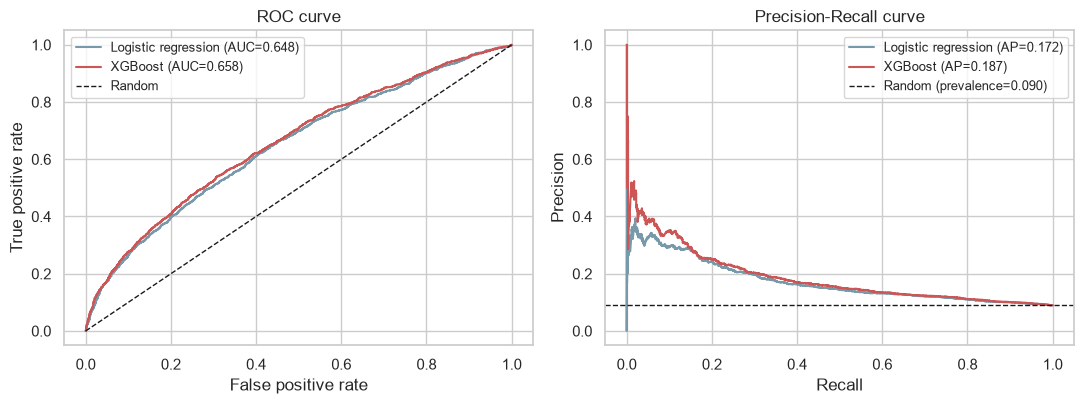

In [10]:
prev = y_test.mean()
fig, ax = plt.subplots(1, 2, figsize=(11, 4.2))
for name, p, col in [("Logistic regression", p_lr, "#79a"), ("XGBoost", p_xgb, "#c55")]:
    fpr, tpr, _ = roc_curve(y_test, p)
    ax[0].plot(fpr, tpr, color=col, label=f"{name} (AUC={roc_auc_score(y_test, p):.3f})")
    pr, rc, _ = precision_recall_curve(y_test, p)
    ax[1].plot(rc, pr, color=col, label=f"{name} (AP={average_precision_score(y_test, p):.3f})")
ax[0].plot([0, 1], [0, 1], "k--", lw=1, label="Random"); ax[0].set(xlabel="False positive rate", ylabel="True positive rate", title="ROC curve")
ax[1].axhline(prev, color="k", ls="--", lw=1, label=f"Random (prevalence={prev:.3f})"); ax[1].set(xlabel="Recall", ylabel="Precision", title="Precision-Recall curve")
for a in ax: a.legend(loc="best", fontsize=9)
plt.tight_layout(); plt.savefig("figures/roc_pr.png", dpi=160); plt.show()

### Choosing a decision threshold
A model outputs a *score*; a hospital needs a *yes/no* flag. A practical rule: **flag the top 20% highest-risk
patients** (matching the capacity of a follow-up team). We then report how many true readmissions we catch.

Flagging top 20% -> sensitivity (recall) = 0.388, PPV (precision) = 0.174, lift over random = 1.94x


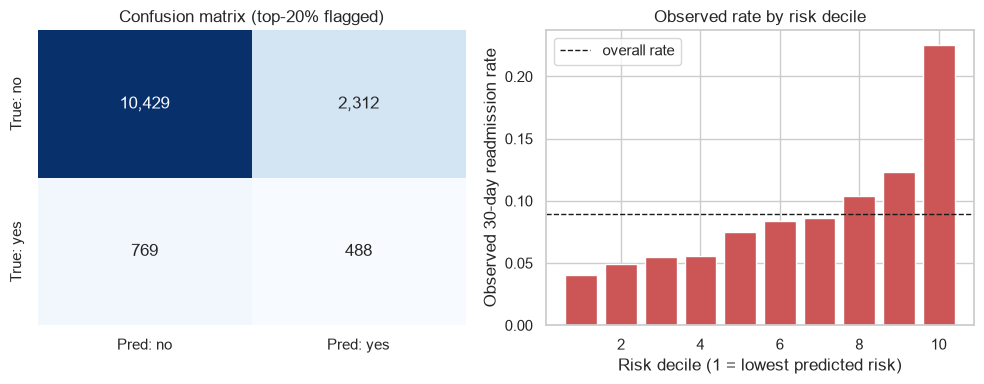

In [11]:
threshold = np.quantile(p_xgb, 0.80)          # top-20% risk cut-off
y_hat = (p_xgb >= threshold).astype(int)
tn, fp, fn, tp = confusion_matrix(y_test, y_hat).ravel()
sens, ppv = tp / (tp + fn), tp / (tp + fp)
print(f"Flagging top 20% -> sensitivity (recall) = {sens:.3f}, PPV (precision) = {ppv:.3f}, "
      f"lift over random = {ppv / prev:.2f}x")

fig, ax = plt.subplots(1, 2, figsize=(10, 4))
sns.heatmap([[tn, fp], [fn, tp]], annot=True, fmt=",", cmap="Blues", cbar=False, ax=ax[0],
            xticklabels=["Pred: no", "Pred: yes"], yticklabels=["True: no", "True: yes"])
ax[0].set_title("Confusion matrix (top-20% flagged)")
# Calibrated view: rescale scores by rank into deciles and show observed readmission rate per decile.
dec = pd.qcut(p_xgb, 10, labels=False)
obs = pd.Series(y_test).groupby(dec).mean()
ax[1].bar(obs.index + 1, obs.values, color="#c55"); ax[1].axhline(prev, color="k", ls="--", lw=1, label="overall rate")
ax[1].set(xlabel="Risk decile (1 = lowest predicted risk)", ylabel="Observed 30-day readmission rate", title="Observed rate by risk decile"); ax[1].legend()
plt.tight_layout(); plt.savefig("figures/threshold.png", dpi=160); plt.show()

## Step 9 — Explain the model with SHAP
**SHAP** (SHapley Additive exPlanations) splits each prediction into contributions from each feature,
based on cooperative game theory. For tree models `shap.TreeExplainer` computes exact values quickly.

* **Global view (beeswarm):** each dot is one patient. Position = how much that feature pushed the risk
  up (right) or down (left). Color = the feature's value (red = high).
* **Local view (waterfall):** why *this specific patient* was flagged, which is what a clinician would want to see.

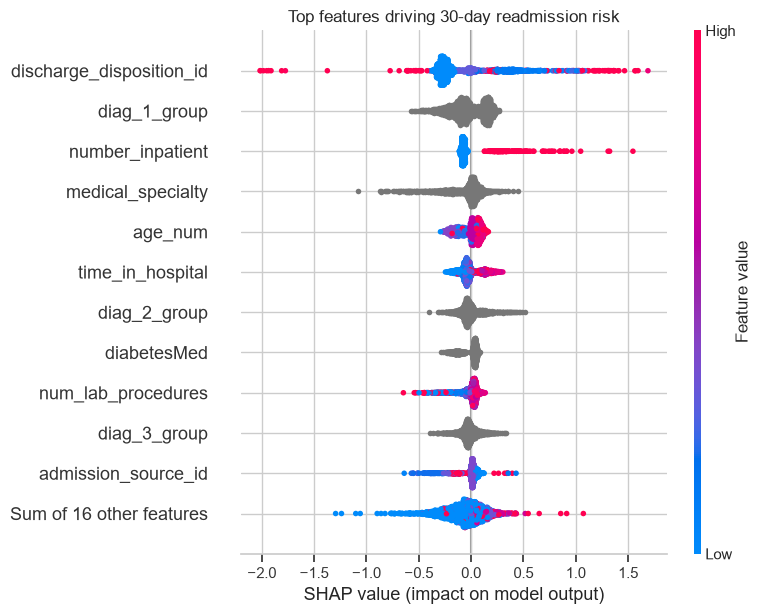

In [12]:
explainer = shap.TreeExplainer(model)
sample = Xte.sample(2000, random_state=SEED)          # a sample keeps plotting fast
shap_values = explainer(sample)

plt.figure()
shap.plots.beeswarm(shap_values, max_display=12, show=False)
plt.title("Top features driving 30-day readmission risk"); plt.tight_layout()
plt.savefig("figures/shap_beeswarm.png", dpi=160, bbox_inches="tight"); plt.show()

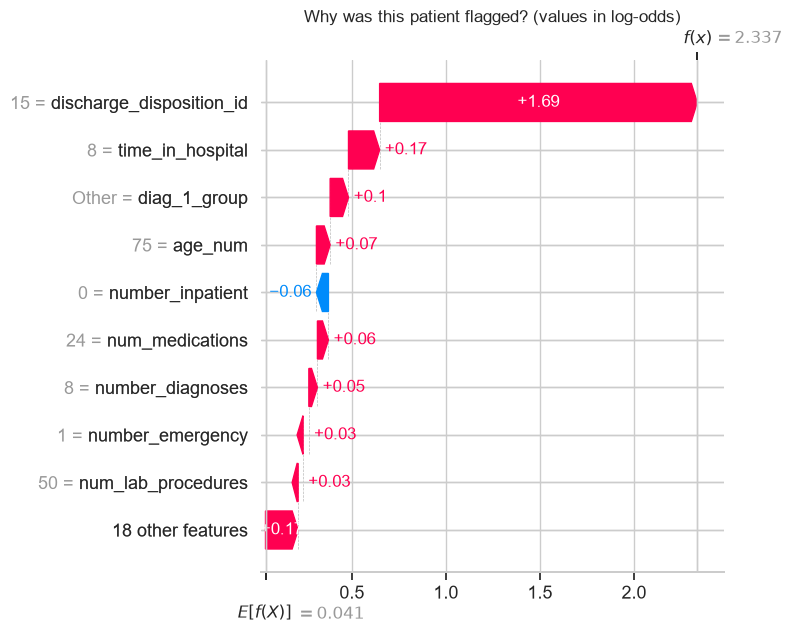

In [13]:
# Explain the single highest-risk patient in our sample.
idx = int(np.argmax(model.predict_proba(sample)[:, 1]))
plt.figure()
shap.plots.waterfall(shap_values[idx], max_display=10, show=False)
plt.title("Why was this patient flagged? (values in log-odds)"); plt.tight_layout()
plt.savefig("figures/shap_waterfall.png", dpi=160, bbox_inches="tight"); plt.show()

**Interpreting codes:** `discharge_disposition_id` is a code (see `IDS_mapping.csv` in the download). Common values:
1 = home, 3 = skilled nursing facility (SNF), 6 = home with home-health, 15 = swing bed within the same hospital,
22 = rehab facility, 28 = psychiatric hospital. Discharge to another care setting signals a sicker, less independent
patient, which is why this feature dominates. Note that SHAP values for XGBoost are in **log-odds** units.

## Step 10 — Fairness check: does the model work equally well for everyone?
A model can have a good overall AUC but perform poorly for a subgroup. We compute ROC-AUC per
group in the test set. Large gaps would need investigation before any clinical use.

In [14]:
rows = []
test_df = X_test.assign(y=y_test, p=p_xgb)
test_df["age_group"] = pd.cut(test_df["age_num"], [0, 50, 70, 100], labels=["<50", "50-69", "70+"])
for col in ["gender", "race", "age_group"]:
    for g, sub in test_df.groupby(col, observed=True):
        if sub["y"].nunique() == 2 and len(sub) >= 200:      # skip groups too small to evaluate
            rows.append({"attribute": col, "group": g, "n": len(sub),
                         "readmit_rate": sub["y"].mean(), "roc_auc": roc_auc_score(sub["y"], sub["p"])})
fair = pd.DataFrame(rows).round(3)
fair

,attribute,group,n,readmit_rate,roc_auc
0,gender,Female,7507,0.088,0.665
1,gender,Male,6491,0.091,0.650
2,race,AfricanAmerican,2504,0.092,0.679
3,race,Caucasian,10522,0.091,0.649
4,race,Hispanic,286,0.105,0.692
5,race,Missing,361,0.061,0.651
6,race,Other,229,0.048,0.776
7,age_group,<50,2231,0.067,0.685
8,age_group,50-69,5591,0.084,0.647
9,age_group,70+,6176,0.103,0.649


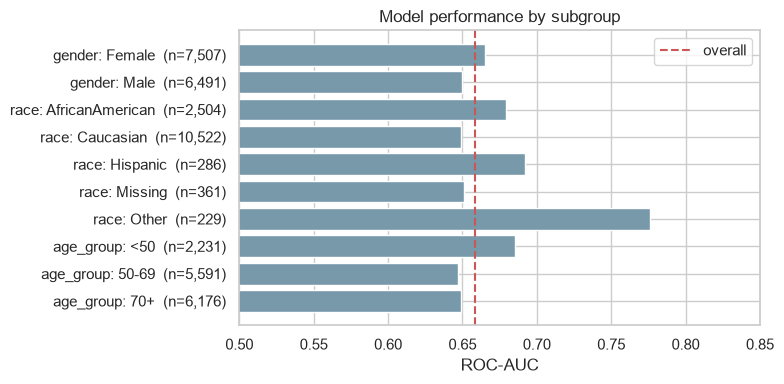

In [15]:
fig, ax = plt.subplots(figsize=(8, 4))
lbl = fair["attribute"] + ": " + fair["group"].astype(str) + "  (n=" + fair["n"].map("{:,}".format) + ")"
ax.barh(lbl, fair["roc_auc"], color="#79a"); ax.axvline(roc_auc_score(y_test, p_xgb), color="#c55", ls="--", label="overall")
ax.set_xlim(0.5, 0.85); ax.set_xlabel("ROC-AUC"); ax.set_title("Model performance by subgroup"); ax.legend(); ax.invert_yaxis()
plt.tight_layout(); plt.savefig("figures/fairness.png", dpi=160); plt.show()

**How to read this:** AUC differences of a few points between large groups (gender, age) are modest. Small groups
(n < ~500, e.g. "Hispanic", "Other") have very wide uncertainty, so a high AUC there is **not** evidence that the model
works better; it is mostly noise. A next step would be bootstrap confidence intervals per group.

## Step 11 — Save a results summary

In [16]:
results = {
    "n_encounters_raw": int(len(df_raw)), "n_patients_after_cleaning": int(len(df)),
    "prevalence": round(float(df["target"].mean()), 3),
    "logreg_roc_auc": round(roc_auc_score(y_test, p_lr), 3), "logreg_pr_auc": round(average_precision_score(y_test, p_lr), 3),
    "xgb_roc_auc": round(roc_auc_score(y_test, p_xgb), 3), "xgb_pr_auc": round(average_precision_score(y_test, p_xgb), 3),
    "xgb_trees": int(model.best_iteration + 1),
    "top20_sensitivity": round(float(sens), 3), "top20_ppv": round(float(ppv), 3), "top20_lift": round(float(ppv / prev), 2),
    "top_shap_features": pd.Series(np.abs(shap_values.values).mean(0), index=sample.columns).sort_values(ascending=False).head(8).astype(float).round(3).to_dict(),
}
with open("figures/results.json", "w") as f:
    json.dump(results, f, indent=2)
results

{'n_encounters_raw': 101766,
 'n_patients_after_cleaning': 69987,
 'prevalence': 0.09,
 'logreg_roc_auc': 0.648,
 'logreg_pr_auc': 0.172,
 'xgb_roc_auc': 0.658,
 'xgb_pr_auc': 0.187,
 'xgb_trees': 304,
 'top20_sensitivity': 0.388,
 'top20_ppv': 0.174,
 'top20_lift': 1.94,
 'top_shap_features': {'discharge_disposition_id': 0.29,
  'diag_1_group': 0.14,
  'number_inpatient': 0.105,
  'medical_specialty': 0.093,
  'age_num': 0.078,
  'time_in_hospital': 0.076,
  'diag_2_group': 0.068,
  'diabetesMed': 0.059}}

## Takeaways
1. **Clean before you model.** Removing deceased/hospice patients and repeat encounters gives an honest estimate.
2. **Readmission is hard to predict from administrative data.** ROC-AUC in the mid-0.6s is typical in the
   literature for this dataset. Social factors (housing, caregiver support, transportation) that drive
   readmission are *not* in the data.
3. **Prior inpatient visits and discharge destination dominate.** Patients who were admitted often in the past
   year, or discharged to another facility, are at highest risk. This matches clinical intuition.
4. **Use PR-AUC and lift for rare outcomes**, and choose thresholds that match real-world capacity.
5. **Explain and audit.** SHAP and subgroup analysis turn a black box into something clinicians can question.

## Try it yourself (exercises)
* Use *all* encounters with a **grouped split** (`GroupShuffleSplit` on `patient_nbr`) and compare to this approach.
* Add features: number of distinct diagnoses, insulin-dose-change × A1C result interaction.
* Tune hyper-parameters with `RandomizedSearchCV` or Optuna and see if AUC improves.
* Replace `scale_pos_weight` with post-hoc **calibration** (`CalibratedClassifierCV`) and plot a reliability diagram.

## References
* Strack B. et al. (2014). *Impact of HbA1c Measurement on Hospital Readmission Rates: Analysis of 70,000 Clinical Database Patient Records.* BioMed Research International, 781670.
* Chen T., Guestrin C. (2016). *XGBoost: A Scalable Tree Boosting System.* KDD.
* Lundberg S., Lee S.-I. (2017). *A Unified Approach to Interpreting Model Predictions.* NeurIPS.
* UCI Machine Learning Repository: Diabetes 130-US Hospitals for Years 1999–2008. https://archive.ics.uci.edu/dataset/296